# 02 · Quantos anos usar no treino

Fase 2 do [`docs/workflow.md`](../docs/workflow.md): perceber os dados antes de treinar.
Os resultados e as decisões que saem daqui estão escritos em [`docs/qualidade_dados.md`](../docs/qualidade_dados.md).

## Como ler este notebook

Cada medição tem quatro partes:

1. **Pergunta**: o que queremos saber dos dados.
2. **Porque importa**: o que muda no modelo conforme a resposta.
3. **Código e resultado.**
4. **Como ler**: o que seria um resultado bom, mau ou estranho, e o que decidimos.

## Como correr

- No VS Code: abrir este ficheiro, escolher o kernel do `.venv` (canto superior direito) e carregar em "Run All".
- No terminal: `.venv/bin/jupyter nbconvert --to notebook --execute --inplace notebooks/02_anos_treino.ipynb`

Corre sempre de cima para baixo. Se os números mudarem depois de atualizar os dados, é preciso atualizar também o `qualidade_dados.md`.

## Regra principal: não espreitar o teste

Os contratos publicados em novembro e dezembro de 2025 são o **teste** e não entram aqui. Aqui o treino é tudo o que foi publicado **antes de outubro de 2025**, desde o ano que se escolher. A **validação** (outubro de 2025) serve para comparar as janelas de anos: é para isso que existe.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))
import cpv_data as cd

pd.set_option("display.max_colwidth", 90)

# Estilo dos gráficos: fundo claro, eixos discretos, uma cor por série
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#3d3d3a",
    "xtick.color": "#3d3d3a", "ytick.color": "#3d3d3a",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e8e7e1", "grid.linewidth": 0.8,
    "font.size": 11,
})
AZUL, LARANJA = "#2a78d6", "#eb6834"

## Quantos anos usar no treino

**Pergunta:** juntar anos anteriores a 2025 ao treino ajuda?

**Porque importa:** na secção 10 do [`01_exploracao.ipynb`](01_exploracao.ipynb) vimos que metade dos códigos tem 4 exemplos ou menos num ano. Mais anos dão mais exemplos aos códigos raros. Mas dados antigos podem ser diferentes dos de hoje (outras regras, outra forma de escrever), e mais dados tornam o treino mais lento e mais caro.

**O que se mede:** para várias janelas de treino, sempre a acabar em setembro de 2025:
- quantos contratos e códigos há;
- quantos contratos da **validação** (outubro de 2025) têm um código que aparece no treino pelo menos 1 vez e pelo menos 10 vezes.

O teste (novembro e dezembro de 2025) continua de fora. Aplicam-se as mesmas regras de antes: uma cópia por `idcontrato`, sem CPV vazio, sem códigos ao nível da divisão.

In [2]:
anos = range(2012, 2027)
hist = cd.load_contracts(["CPV"], years=anos)
hist["codigo"] = cd.first_code(hist["CPV"])
hist = (hist.dropna(subset=["codigo", "data"])
            .sort_values("data")
            .drop_duplicates("idcontrato", keep="last"))
hist["nivel"] = cd.code_level(hist["codigo"])
hist["ano"] = hist["data"].dt.year

antes_val = hist[hist["data"] < cd.VAL_START]
val = hist[(hist["data"] >= cd.VAL_START) & (hist["data"] < cd.TEST_START) & (hist["nivel"] > 2)]
assert antes_val["data"].max() < cd.VAL_START
print("Contratos publicados antes de outubro de 2025:", len(antes_val))
print("Validação (outubro de 2025, sem códigos ao nível da divisão):", len(val))

Contratos publicados antes de outubro de 2025: 1993408
Validação (outubro de 2025, sem códigos ao nível da divisão): 19894


Primeiro, por ano de publicação: quantos contratos há, e se a qualidade das etiquetas muda com o tempo (percentagem de códigos ao nível da divisão).

In [3]:
por_ano = antes_val.groupby("ano").agg(
    contratos=("codigo", "size"),
    pct_nivel_divisao=("nivel", lambda s: (s == 2).mean()),
)
por_ano = por_ano[por_ano.index >= 2012]
por_ano.style.format({"pct_nivel_divisao": "{:.1%}", "contratos": "{:,}"})

,contratos,pct_nivel_divisao
ano,,
2012,"53,263",7.1%
2013,"75,599",25.8%
2014,"92,137",25.8%
2015,"112,280",25.4%
2016,"114,592",24.7%
2017,"127,723",22.7%
2018,"122,048",22.4%
2019,"144,750",19.6%
2020,"164,043",20.1%


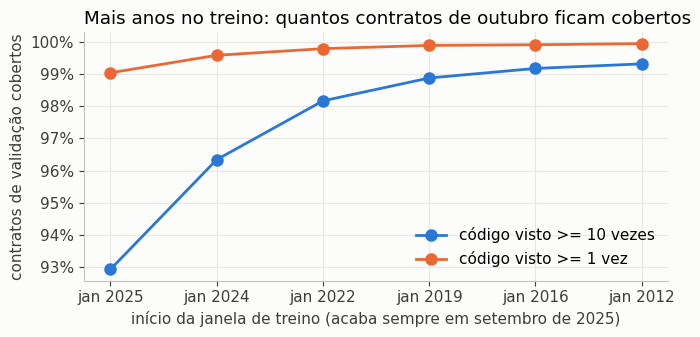

,contratos de treino,códigos distintos,códigos com >= 10 exemplos,validação: código visto >= 1 vez,validação: código visto >= 10 vezes
treino desde,,,,,
jan 2025,"159,030","4,450","1,496",99.0%,92.9%
jan 2024,"338,013","5,356","2,214",99.6%,96.3%
jan 2022,"645,625","6,138","3,038",99.8%,98.2%
jan 2019,"1,040,375","6,692","3,709",99.9%,98.9%
jan 2016,"1,320,043","6,978","4,068",99.9%,99.2%
jan 2012,"1,577,637","7,314","4,429",99.9%,99.3%


In [4]:
inicio = [2025, 2024, 2022, 2019, 2016, 2012]
linhas = []
for a in inicio:
    tr = antes_val[(antes_val["ano"] >= a) & (antes_val["nivel"] > 2)]
    vc = tr["codigo"].value_counts()
    linhas.append({
        "treino desde": f"jan {a}",
        "contratos de treino": len(tr),
        "códigos distintos": len(vc),
        "códigos com >= 10 exemplos": int((vc >= 10).sum()),
        "validação: código visto >= 1 vez": val["codigo"].isin(vc.index).mean(),
        "validação: código visto >= 10 vezes": val["codigo"].isin(vc[vc >= 10].index).mean(),
    })
janelas = pd.DataFrame(linhas).set_index("treino desde")

fig, ax = plt.subplots(figsize=(7, 3.5))
x = range(len(janelas))
ax.plot(x, janelas["validação: código visto >= 10 vezes"], color=AZUL, linewidth=2, marker="o", markersize=8, label="código visto >= 10 vezes")
ax.plot(x, janelas["validação: código visto >= 1 vez"], color=LARANJA, linewidth=2, marker="o", markersize=8, label="código visto >= 1 vez")
ax.set_xticks(list(x), janelas.index)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("início da janela de treino (acaba sempre em setembro de 2025)")
ax.set_ylabel("contratos de validação cobertos")
ax.set_title("Mais anos no treino: quantos contratos de outubro ficam cobertos", loc="left")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

janelas.style.format({
    "contratos de treino": "{:,}", "códigos distintos": "{:,}", "códigos com >= 10 exemplos": "{:,}",
    "validação: código visto >= 1 vez": "{:.1%}", "validação: código visto >= 10 vezes": "{:.1%}",
})

**Como ler:**
- A coluna mais importante é **"validação: código visto >= 10 vezes"**: dos contratos novos de outubro, quantos têm um código com exemplos suficientes para o modelo o aprender. Se sobe muito com mais anos, vale a pena juntá-los.
- Se a subida for pequena, mais anos só trazem mais custo.
- A tabela por ano mostra se os anos antigos têm etiquetas piores (mais códigos ao nível da divisão).
- **Isto é uma estimativa.** Ter o código no treino não garante que o modelo acerta. A resposta definitiva vem da fase 4: treinar o modelo simples (TF-IDF) com cada janela e ver qual dá melhor resultado na validação.